<a href="https://colab.research.google.com/github/boddanapurna6-oss/Deep-Learning-skills/blob/main/Week_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q pycocotools opencv-python matplotlib seaborn pandas tqdm


In [2]:

import os
import cv2
import json
import random
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from pycocotools.coco import COCO

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

import zipfile

annotation_url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
zip_path = "/content/coco_annotations.zip"

if not os.path.exists("/content/annotations/instances_val2017.json"):
    print("Downloading COCO annotations...")
    response = requests.get(annotation_url)
    with open(zip_path, "wb") as f:
        f.write(response.content)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("/content")

annotation_path = "/content/annotations/instances_val2017.json"

coco = COCO(annotation_path)

print("COCO dataset loaded successfully!")


loading annotations into memory...
Done (t=1.00s)
creating index...
index created!
COCO dataset loaded successfully!


In [4]:

traffic_categories = [
    "car",
    "motorcycle",
    "bus",
    "truck",
    "bicycle",
    "person",
    "traffic light",
    "stop sign"
]

category_ids = {}

for category in coco.loadCats(coco.getCatIds()):
    if category["name"] in traffic_categories:
        category_ids[category["name"]] = category["id"]

print("Traffic Categories:")
for name, cat_id in category_ids.items():
    print(name, ":", cat_id)


Traffic Categories:
person : 1
bicycle : 2
car : 3
motorcycle : 4
bus : 6
truck : 8
traffic light : 10
stop sign : 13


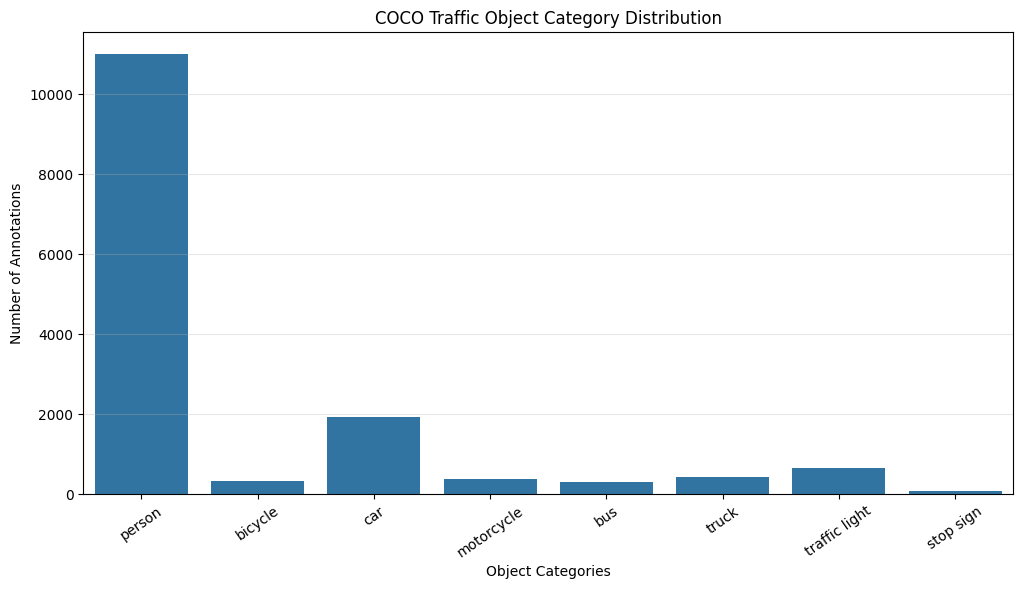

        Category  Count
0         person  11004
1        bicycle    316
2            car   1932
3     motorcycle    371
4            bus    285
5          truck    415
6  traffic light    637
7      stop sign     75


In [5]:

category_counts = {}

for name, cat_id in category_ids.items():
    ann_ids = coco.getAnnIds(catIds=[cat_id])
    category_counts[name] = len(ann_ids)

df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Count"]
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Category",
    y="Count"
)

plt.title("COCO Traffic Object Category Distribution")
plt.xlabel("Object Categories")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.show()

print(df)


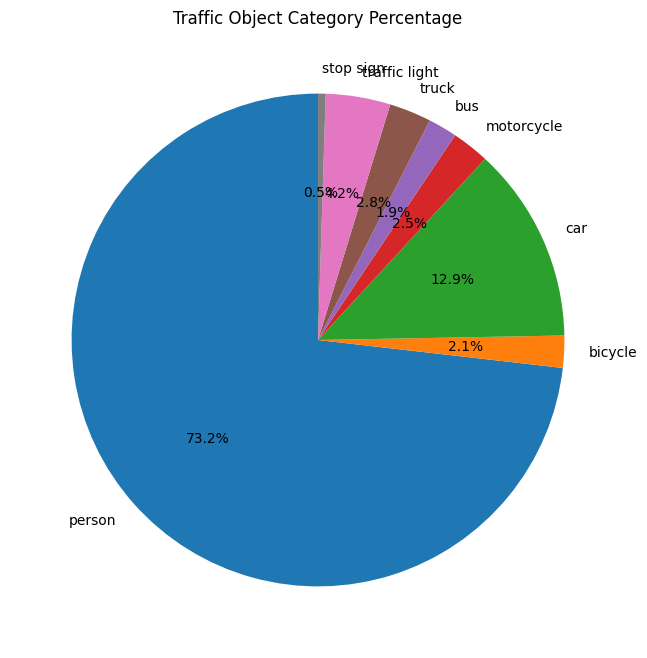

In [6]:

plt.figure(figsize=(8, 8))

plt.pie(
    df["Count"],
    labels=df["Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Traffic Object Category Percentage")
plt.show()


In [7]:

image_ids = set()

for cat_id in category_ids.values():
    image_ids.update(coco.getImgIds(catIds=[cat_id]))

image_ids = list(image_ids)
random.seed(42)

selected_ids = random.sample(
    image_ids,
    min(6, len(image_ids))
)

os.makedirs("/content/traffic_images", exist_ok=True)

selected_images = []

for img_id in selected_ids:
    img_info = coco.loadImgs(img_id)[0]

    image_url = img_info["coco_url"]
    image_path = f"/content/traffic_images/{img_id}.jpg"

    response = requests.get(image_url)

    if response.status_code == 200:
        with open(image_path, "wb") as f:
            f.write(response.content)

        selected_images.append((img_info, image_path))

print("Downloaded images:", len(selected_images))


Downloaded images: 6


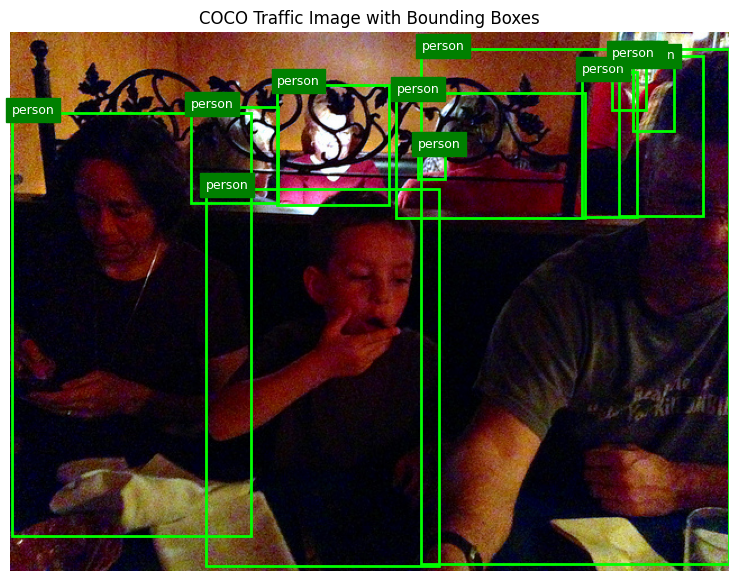

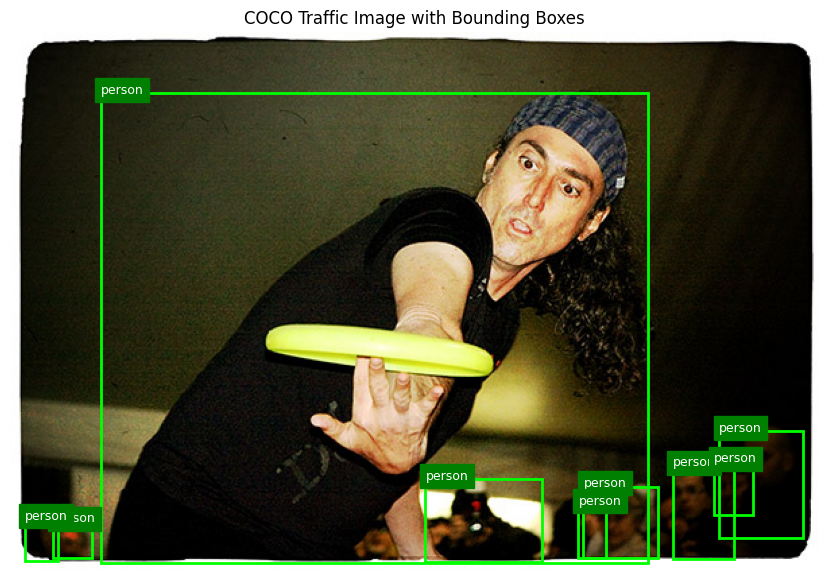

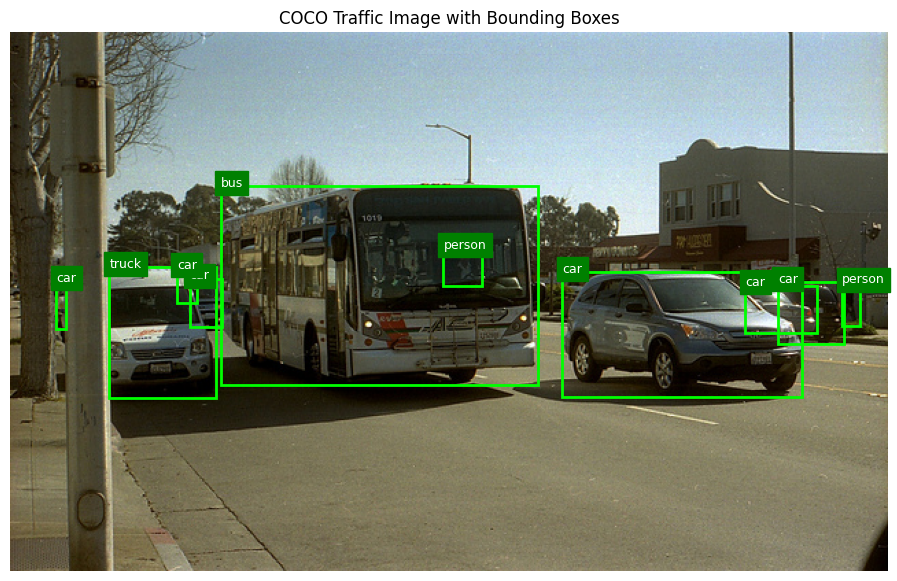

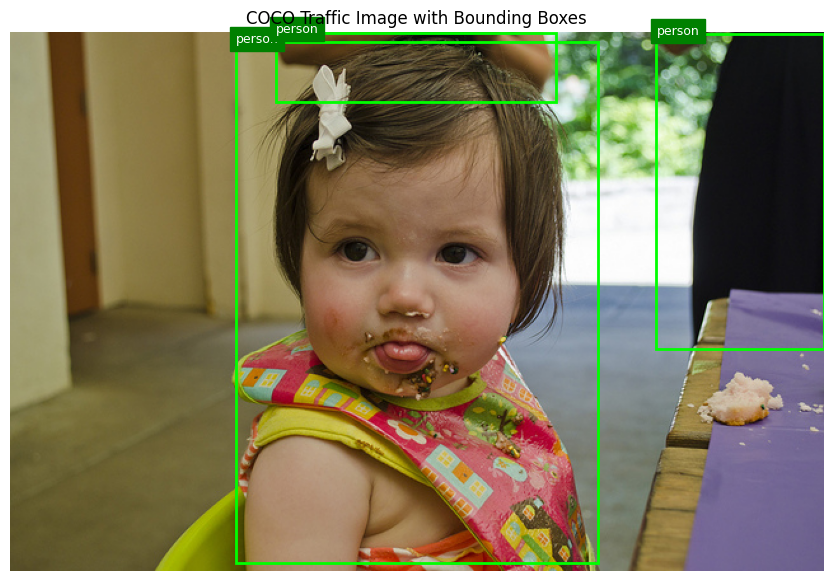

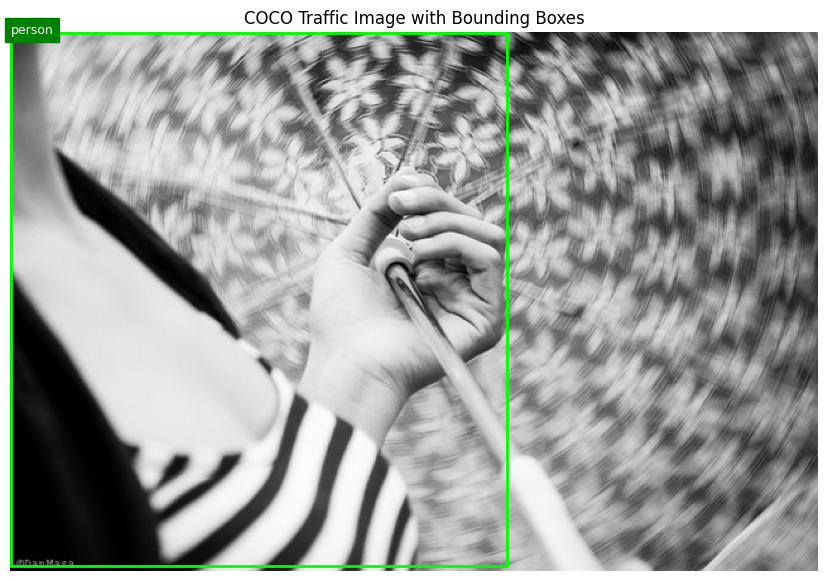

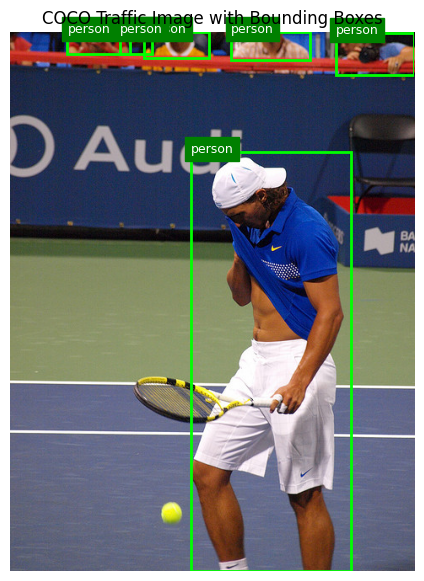

In [8]:

for img_info, image_path in selected_images:

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ann_ids = coco.getAnnIds(
        imgIds=[img_info["id"]],
        catIds=list(category_ids.values())
    )

    annotations = coco.loadAnns(ann_ids)

    plt.figure(figsize=(12, 7))
    plt.imshow(image)

    ax = plt.gca()

    for ann in annotations:
        x, y, w, h = ann["bbox"]

        category_name = coco.loadCats(
            [ann["category_id"]]
        )[0]["name"]

        rectangle = plt.Rectangle(
            (x, y), w, h,
            fill=False,
            edgecolor="lime",
            linewidth=2
        )

        ax.add_patch(rectangle)

        ax.text(
            x, y,
            category_name,
            color="white",
            fontsize=9,
            backgroundcolor="green"
        )

    plt.title("COCO Traffic Image with Bounding Boxes")
    plt.axis("off")
    plt.show()


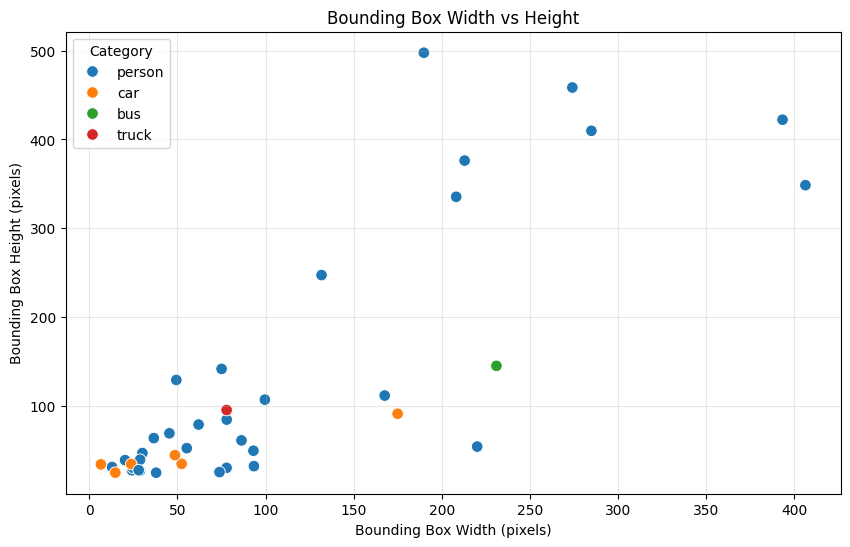

  Category   Width  Height         Area
0   person  274.08  458.47  125657.4576
1   person  208.18  335.46   69836.0628
2   person   99.64  107.15   10676.4260
3   person  212.97  376.22   80123.5734
4   person   49.41  129.28    6387.7248
5   person   36.62   63.86    2338.5532
6   person   75.07  141.72   10638.9204
7   person  167.62  111.74   18729.8588
8   person   77.99   84.69    6604.9731
9   person   24.23   27.70     671.1710


In [9]:

bbox_data = []

for img_info, image_path in selected_images:

    ann_ids = coco.getAnnIds(
        imgIds=[img_info["id"]],
        catIds=list(category_ids.values())
    )

    annotations = coco.loadAnns(ann_ids)

    for ann in annotations:
        x, y, w, h = ann["bbox"]

        bbox_data.append({
            "Category": coco.loadCats(
                [ann["category_id"]]
            )[0]["name"],
            "Width": w,
            "Height": h,
            "Area": w * h
        })

bbox_df = pd.DataFrame(bbox_data)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=bbox_df,
    x="Width",
    y="Height",
    hue="Category",
    s=70
)

plt.title("Bounding Box Width vs Height")
plt.xlabel("Bounding Box Width (pixels)")
plt.ylabel("Bounding Box Height (pixels)")
plt.grid(alpha=0.3)
plt.show()

print(bbox_df.head(10))


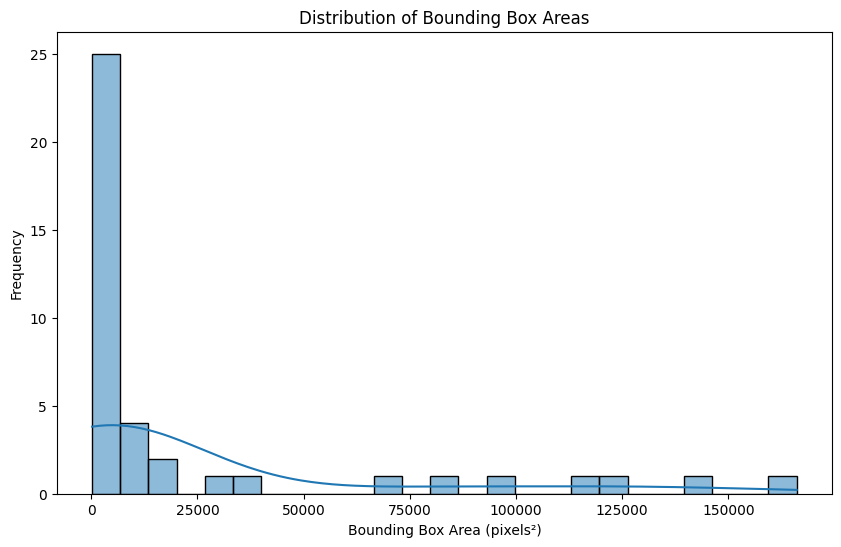

In [10]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=bbox_df,
    x="Area",
    bins=25,
    kde=True
)

plt.title("Distribution of Bounding Box Areas")
plt.xlabel("Bounding Box Area (pixels²)")
plt.ylabel("Frequency")
plt.show()


In [11]:

print("========== COCO DATASET ANALYSIS ==========")

print("Total selected images:", len(selected_images))

print("Total traffic annotations:",
      len(bbox_df))

print("\nCategory-wise annotation count:")
print(bbox_df["Category"].value_counts())

print("\nAverage bounding box width:",
      round(bbox_df["Width"].mean(), 2))

print("Average bounding box height:",
      round(bbox_df["Height"].mean(), 2))

print("Average bounding box area:",
      round(bbox_df["Area"].mean(), 2))

print("\nProject execution completed successfully!")


========== COCO DATASET ANALYSIS ==========
Total selected images: 6
Total traffic annotations: 40

Category-wise annotation count:
Category
person    32
car        6
bus        1
truck      1
Name: count, dtype: int64

Average bounding box width: 107.03
Average bounding box height: 124.72
Average bounding box area: 24815.28

Project execution completed successfully!
